In [1]:
!pip install -q open3d laspy 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.1/86.1 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 83.3 MB/s eta 0:00:00


In [2]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import laspy

DATASET_PATH = "/kaggle/input/datasets/haruxo/daleslas/dales_las"

TRAIN_PATH = os.path.join(DATASET_PATH, "train")
TEST_PATH = os.path.join(DATASET_PATH, "test")

In [3]:
train_files = glob.glob(os.path.join(TRAIN_PATH, "*.las"))
test_files = glob.glob(os.path.join(TEST_PATH, "*.las"))

print("Training files:", len(train_files))
print("Testing files:", len(test_files))
print("Total files:", len(train_files) + len(test_files))

Training files: 29
Testing files: 11
Total files: 40


In [4]:
print("Sample training files:")
for file in train_files[:10]:
    print(os.path.basename(file))

print("\nSample testing files:")
for file in test_files[:10]:
    print(os.path.basename(file))

Sample training files:
5085_54320.las
5145_54470.las
5095_54455.las
5145_54460.las
5095_54440.las
5115_54480.las
5165_54390.las
5185_54390.las
5180_54435.las
5180_54485.las

Sample testing files:
5135_54430.las
5140_54390.las
5175_54395.las
5150_54325.las
5100_54490.las
5080_54400.las
5080_54470.las
5155_54335.las
5100_54440.las
5120_54445.las


In [5]:
sample_file = train_files[0]

print("Selected file:", sample_file)

Selected file: /kaggle/input/datasets/haruxo/daleslas/dales_las/train/5085_54320.las


In [6]:
las = laspy.read(sample_file)

print(las)

<LasData(1.2, point fmt: <PointFormat(1, 0 bytes of extra dims)>, 14394749 points, 0 vlrs)>


In [7]:
print("Number of points:", len(las.points))
print("Available dimensions:")
print(list(las.point_format.dimension_names))

Number of points: 14394749
Available dimensions:
['X', 'Y', 'Z', 'intensity', 'return_number', 'number_of_returns', 'scan_direction_flag', 'edge_of_flight_line', 'classification', 'synthetic', 'key_point', 'withheld', 'scan_angle_rank', 'user_data', 'point_source_id', 'gps_time']


In [8]:
x = np.array(las.x)
y = np.array(las.y)
z = np.array(las.z)

points = np.column_stack((x, y, z))

print("Point cloud shape:", points.shape)
print("\nFirst 5 points:")
print(points[:5])

Point cloud shape: (14394749, 3)

First 5 points:
[[ 5.08501120e+05  5.43202258e+06 -1.05000000e+00]
 [ 5.08502280e+05  5.43202161e+06 -1.12000000e+00]
 [ 5.08502490e+05  5.43202222e+06 -1.06000000e+00]
 [ 5.08505290e+05  5.43202151e+06 -1.13000000e+00]
 [ 5.08500840e+05  5.43202194e+06 -1.11000000e+00]]


In [9]:
print("Available LAS dimensions:")
for dim in las.point_format.dimension_names:
    print(dim)
classification = np.array(las.classification)

unique_labels, counts = np.unique(classification, return_counts=True)

print("\nClassification Distribution:")

for label, count in zip(unique_labels, counts):
    print(f"Label {label}: {count:,} points")

Available LAS dimensions:
X
Y
Z
intensity
return_number
number_of_returns
scan_direction_flag
edge_of_flight_line
classification
synthetic
key_point
withheld
scan_angle_rank
user_data
point_source_id
gps_time

Classification Distribution:
Label 0: 43,787 points
Label 1: 4,926,289 points
Label 2: 7,014,400 points
Label 3: 69,005 points
Label 4: 6,277 points
Label 5: 4,420 points
Label 6: 33,399 points
Label 7: 4,654 points
Label 8: 2,292,518 points


In [10]:
print("Coordinate Statistics\n")

print("X Range:", x.min(), "to", x.max())
print("Y Range:", y.min(), "to", y.max())
print("Z Range:", z.min(), "to", z.max())

print("\nMean Coordinates:")
print("X Mean:", x.mean())
print("Y Mean:", y.mean())
print("Z Mean:", z.mean())

Coordinate Statistics

X Range: 508500.01 to 509000.05
Y Range: 5431999.92 to 5432499.96
Z Range: -3.0 to 87.60000000000001

Mean Coordinates:
X Mean: 508747.1569826316
Y Mean: 5432253.090170032
Z Mean: 46.03452319383957


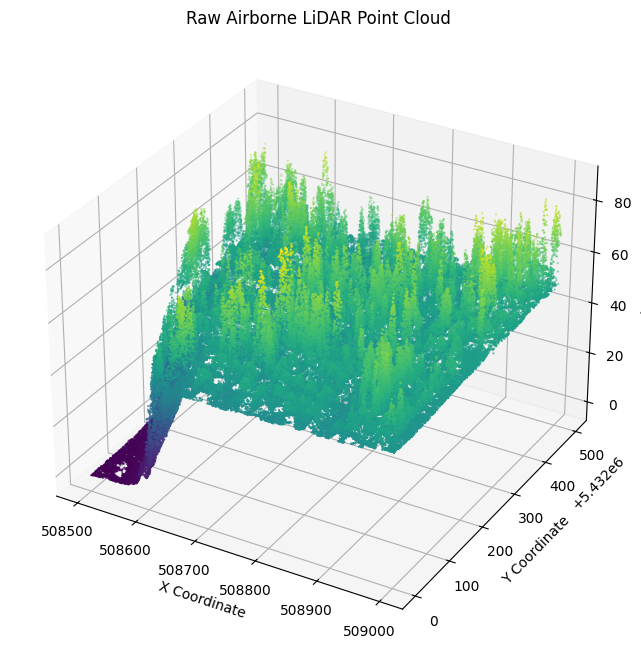

In [11]:
max_points = 200000

if len(points) > max_points:
    indices = np.random.choice(len(points), max_points, replace=False)
    sampled_points = points[indices]
else:
    sampled_points = points

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    sampled_points[:, 0],
    sampled_points[:, 1],
    sampled_points[:, 2],
    s=0.3,
    c=sampled_points[:, 2],
    cmap='viridis'
)

ax.set_title("Raw Airborne LiDAR Point Cloud")
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
ax.set_zlabel("Elevation")

plt.show()

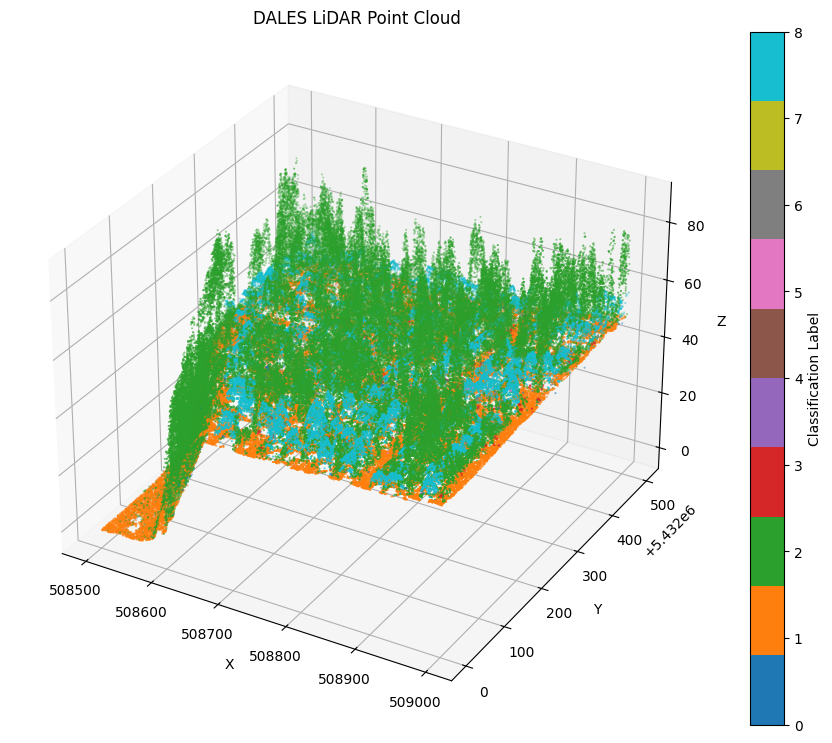

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Sample points for faster visualization
sample_size = min(200000, len(points))
indices = np.random.choice(len(points), sample_size, replace=False)

sample_points = points[indices]
sample_labels = classification[indices]

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    sample_points[:, 0],
    sample_points[:, 1],
    sample_points[:, 2],
    c=sample_labels,
    s=0.2,
    cmap="tab10"
)

ax.set_title("DALES LiDAR Point Cloud")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.colorbar(scatter, ax=ax, label="Classification Label")
plt.show()

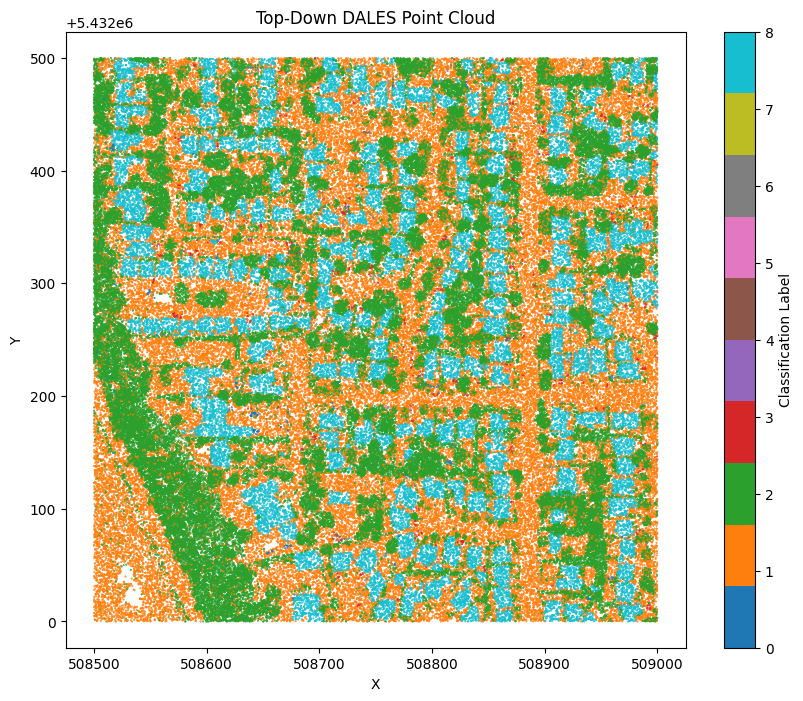

In [13]:
plt.figure(figsize=(10, 8))

plt.scatter(
    sample_points[:, 0],
    sample_points[:, 1],
    c=sample_labels,
    s=0.2,
    cmap="tab10"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Top-Down DALES Point Cloud")
plt.axis("equal")
plt.colorbar(label="Classification Label")
plt.show()

In [14]:
print("Coordinate ranges:")
print("X:", float(las.x.min()), "to", float(las.x.max()))
print("Y:", float(las.y.min()), "to", float(las.y.max()))
print("Z:", float(las.z.min()), "to", float(las.z.max()))

print("\nIntensity range:")
print(int(las.intensity.min()), "to", int(las.intensity.max()))

print("\nReturn number range:")
print(int(las.return_number.min()), "to", int(las.return_number.max()))

print("\nNumber of returns range:")
print(int(las.number_of_returns.min()), "to", int(las.number_of_returns.max()))

Coordinate ranges:
X: 508500.01 to 509000.05
Y: 5431999.92 to 5432499.96
Z: -3.0 to 87.60000000000001

Intensity range:
0 to 0

Return number range:
1 to 7

Number of returns range:
1 to 7


# POINT CLOUD PREPROCESSING


In [15]:
import numpy as np

# Coordinates
points = np.column_stack([
    np.asarray(las.x),
    np.asarray(las.y),
    np.asarray(las.z)
]).astype(np.float32)

# Additional LiDAR features
intensity = np.asarray(las.intensity).astype(np.float32)
return_number = np.asarray(las.return_number).astype(np.float32)
number_of_returns = np.asarray(las.number_of_returns).astype(np.float32)
classification = np.asarray(las.classification).astype(np.int32)

print("Points shape:", points.shape)
print("Intensity shape:", intensity.shape)
print("Classification shape:", classification.shape)

Points shape: (14394749, 3)
Intensity shape: (14394749,)
Classification shape: (14394749,)


In [16]:
print("NaN values in coordinates:", np.isnan(points).sum())
print("Infinite values in coordinates:", np.isinf(points).sum())

print("NaN values in intensity:", np.isnan(intensity).sum())
print("Infinite values in intensity:", np.isinf(intensity).sum())

print("Minimum coordinate values:", points.min(axis=0))
print("Maximum coordinate values:", points.max(axis=0))

NaN values in coordinates: 0
Infinite values in coordinates: 0
NaN values in intensity: 0
Infinite values in intensity: 0
Minimum coordinate values: [ 5.085e+05  5.432e+06 -3.000e+00]
Maximum coordinate values: [5.0900006e+05 5.4325000e+06 8.7599998e+01]


In [17]:
points_original = points.copy()

points_normalized = points - points.min(axis=0)

print("Original minimum:", points_original.min(axis=0))
print("Normalized minimum:", points_normalized.min(axis=0))

print("Normalized maximum:", points_normalized.max(axis=0))

Original minimum: [ 5.085e+05  5.432e+06 -3.000e+00]
Normalized minimum: [0. 0. 0.]
Normalized maximum: [500.0625 500.      90.6   ]


In [18]:
intensity_min = intensity.min()
intensity_max = intensity.max()

intensity_normalized = (
    intensity - intensity_min
) / (
    intensity_max - intensity_min + 1e-8
)

print("Original intensity:", intensity_min, "to", intensity_max)
print(
    "Normalized intensity:",
    intensity_normalized.min(),
    "to",
    intensity_normalized.max()
)

Original intensity: 0.0 to 0.0
Normalized intensity: 0.0 to 0.0


In [19]:
print("Return number distribution:")
unique_returns, return_counts = np.unique(
    return_number,
    return_counts=True
)

for value, count in zip(unique_returns, return_counts):
    print(f"Return {int(value)}: {count:,} points")

print("\nNumber of returns distribution:")
unique_total_returns, total_return_counts = np.unique(
    number_of_returns,
    return_counts=True
)

for value, count in zip(unique_total_returns, total_return_counts):
    print(f"{int(value)} total returns: {count:,} points")

Return number distribution:
Return 1: 9,448,596 points
Return 2: 2,899,342 points
Return 3: 1,336,661 points
Return 4: 518,927 points
Return 5: 151,601 points
Return 6: 33,239 points
Return 7: 6,383 points

Number of returns distribution:
1 total returns: 6,549,264 points
2 total returns: 3,125,902 points
3 total returns: 2,453,354 points
4 total returns: 1,469,033 points
5 total returns: 591,516 points
6 total returns: 165,784 points
7 total returns: 39,896 points


In [20]:
features = np.column_stack([
    points_normalized,
    return_number,
    number_of_returns
]).astype(np.float32)

print("Feature matrix shape:", features.shape)

Feature matrix shape: (14394749, 5)


In [21]:
return_number_normalized = (
    return_number / max(return_number.max(), 1)
)

number_of_returns_normalized = (
    number_of_returns / max(number_of_returns.max(), 1)
)

features = np.column_stack([
    points_normalized,
    return_number_normalized,
    number_of_returns_normalized
]).astype(np.float32)

print("Feature matrix shape:", features.shape)
print("Feature minimum:", features.min(axis=0))
print("Feature maximum:", features.max(axis=0))

Feature matrix shape: (14394749, 5)
Feature minimum: [0.         0.         0.         0.14285715 0.14285715]
Feature maximum: [500.0625 500.      90.6      1.       1.    ]


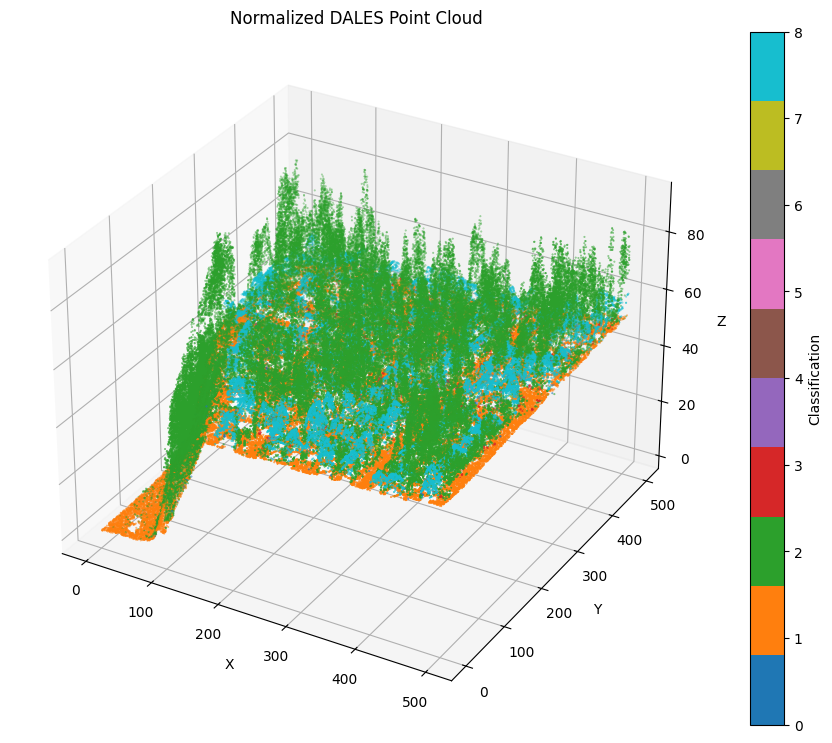

In [22]:
import matplotlib.pyplot as plt

sample_size = min(200000, len(points_normalized))

indices = np.random.choice(
    len(points_normalized),
    sample_size,
    replace=False
)

sample_points = points_normalized[indices]
sample_labels = classification[indices]

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    sample_points[:, 0],
    sample_points[:, 1],
    sample_points[:, 2],
    c=sample_labels,
    s=0.2,
    cmap="tab10"
)

ax.set_title("Normalized DALES Point Cloud")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.colorbar(scatter, ax=ax, label="Classification")
plt.show()

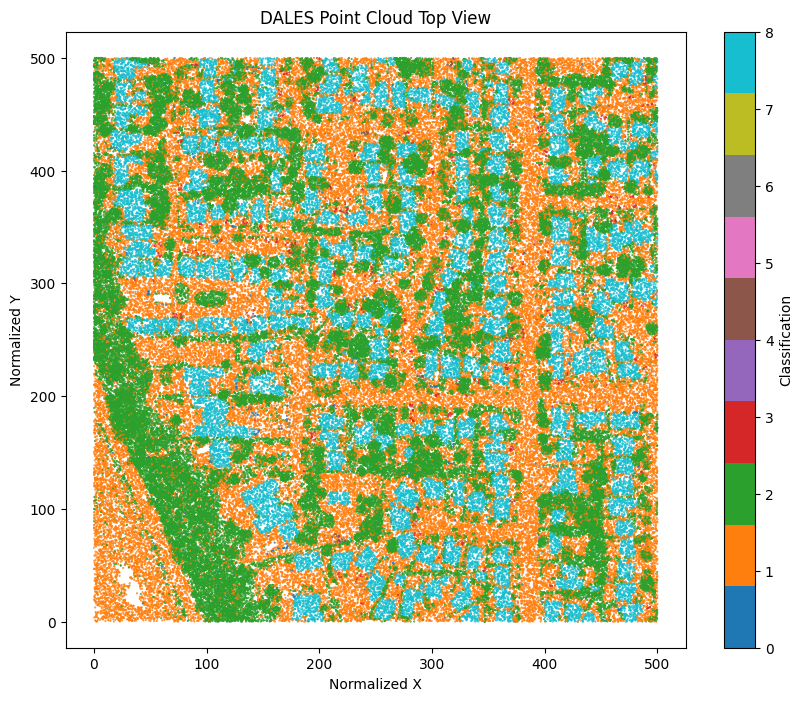

In [23]:
plt.figure(figsize=(10, 8))

plt.scatter(
    sample_points[:, 0],
    sample_points[:, 1],
    c=sample_labels,
    s=0.2,
    cmap="tab10"
)

plt.title("DALES Point Cloud Top View")
plt.xlabel("Normalized X")
plt.ylabel("Normalized Y")
plt.axis("equal")
plt.colorbar(label="Classification")
plt.show()

In [24]:
unique_labels, counts = np.unique(classification, return_counts=True)

for label, count in zip(unique_labels, counts):
    print(f"Label {label}: {count:,} points")

Label 0: 43,787 points
Label 1: 4,926,289 points
Label 2: 7,014,400 points
Label 3: 69,005 points
Label 4: 6,277 points
Label 5: 4,420 points
Label 6: 33,399 points
Label 7: 4,654 points
Label 8: 2,292,518 points


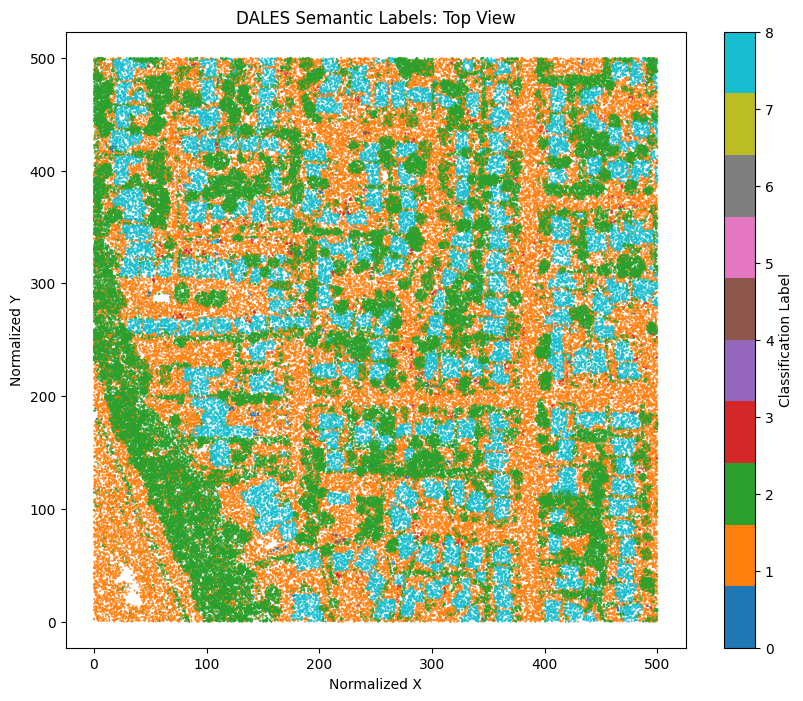

In [25]:
import matplotlib.pyplot as plt

sample_size = min(200000, len(points_normalized))
indices = np.random.choice(
    len(points_normalized),
    sample_size,
    replace=False
)

sample_points = points_normalized[indices]
sample_labels = classification[indices]

plt.figure(figsize=(10, 8))

plt.scatter(
    sample_points[:, 0],
    sample_points[:, 1],
    c=sample_labels,
    s=0.2,
    cmap="tab10"
)

plt.xlabel("Normalized X")
plt.ylabel("Normalized Y")
plt.title("DALES Semantic Labels: Top View")
plt.axis("equal")
plt.colorbar(label="Classification Label")
plt.show()

In [26]:
sample_size = min(500000, len(features))

sample_indices = np.random.choice(
    len(features),
    sample_size,
    replace=False
)

sample_features = features[sample_indices]
sample_classification = classification[sample_indices]

np.save("/kaggle/working/sample_features.npy", sample_features)
np.save("/kaggle/working/sample_labels.npy", sample_classification)

print("Saved sample features:", sample_features.shape)
print("Saved sample labels:", sample_classification.shape)

Saved sample features: (500000, 5)
Saved sample labels: (500000,)


# Identify Building Labels

In [27]:
unique_labels, counts = np.unique(
    classification,
    return_counts=True
)

print("Classification labels:")
for label, count in zip(unique_labels, counts):
    print(f"Label {label}: {count:,} points")

Classification labels:
Label 0: 43,787 points
Label 1: 4,926,289 points
Label 2: 7,014,400 points
Label 3: 69,005 points
Label 4: 6,277 points
Label 5: 4,420 points
Label 6: 33,399 points
Label 7: 4,654 points
Label 8: 2,292,518 points


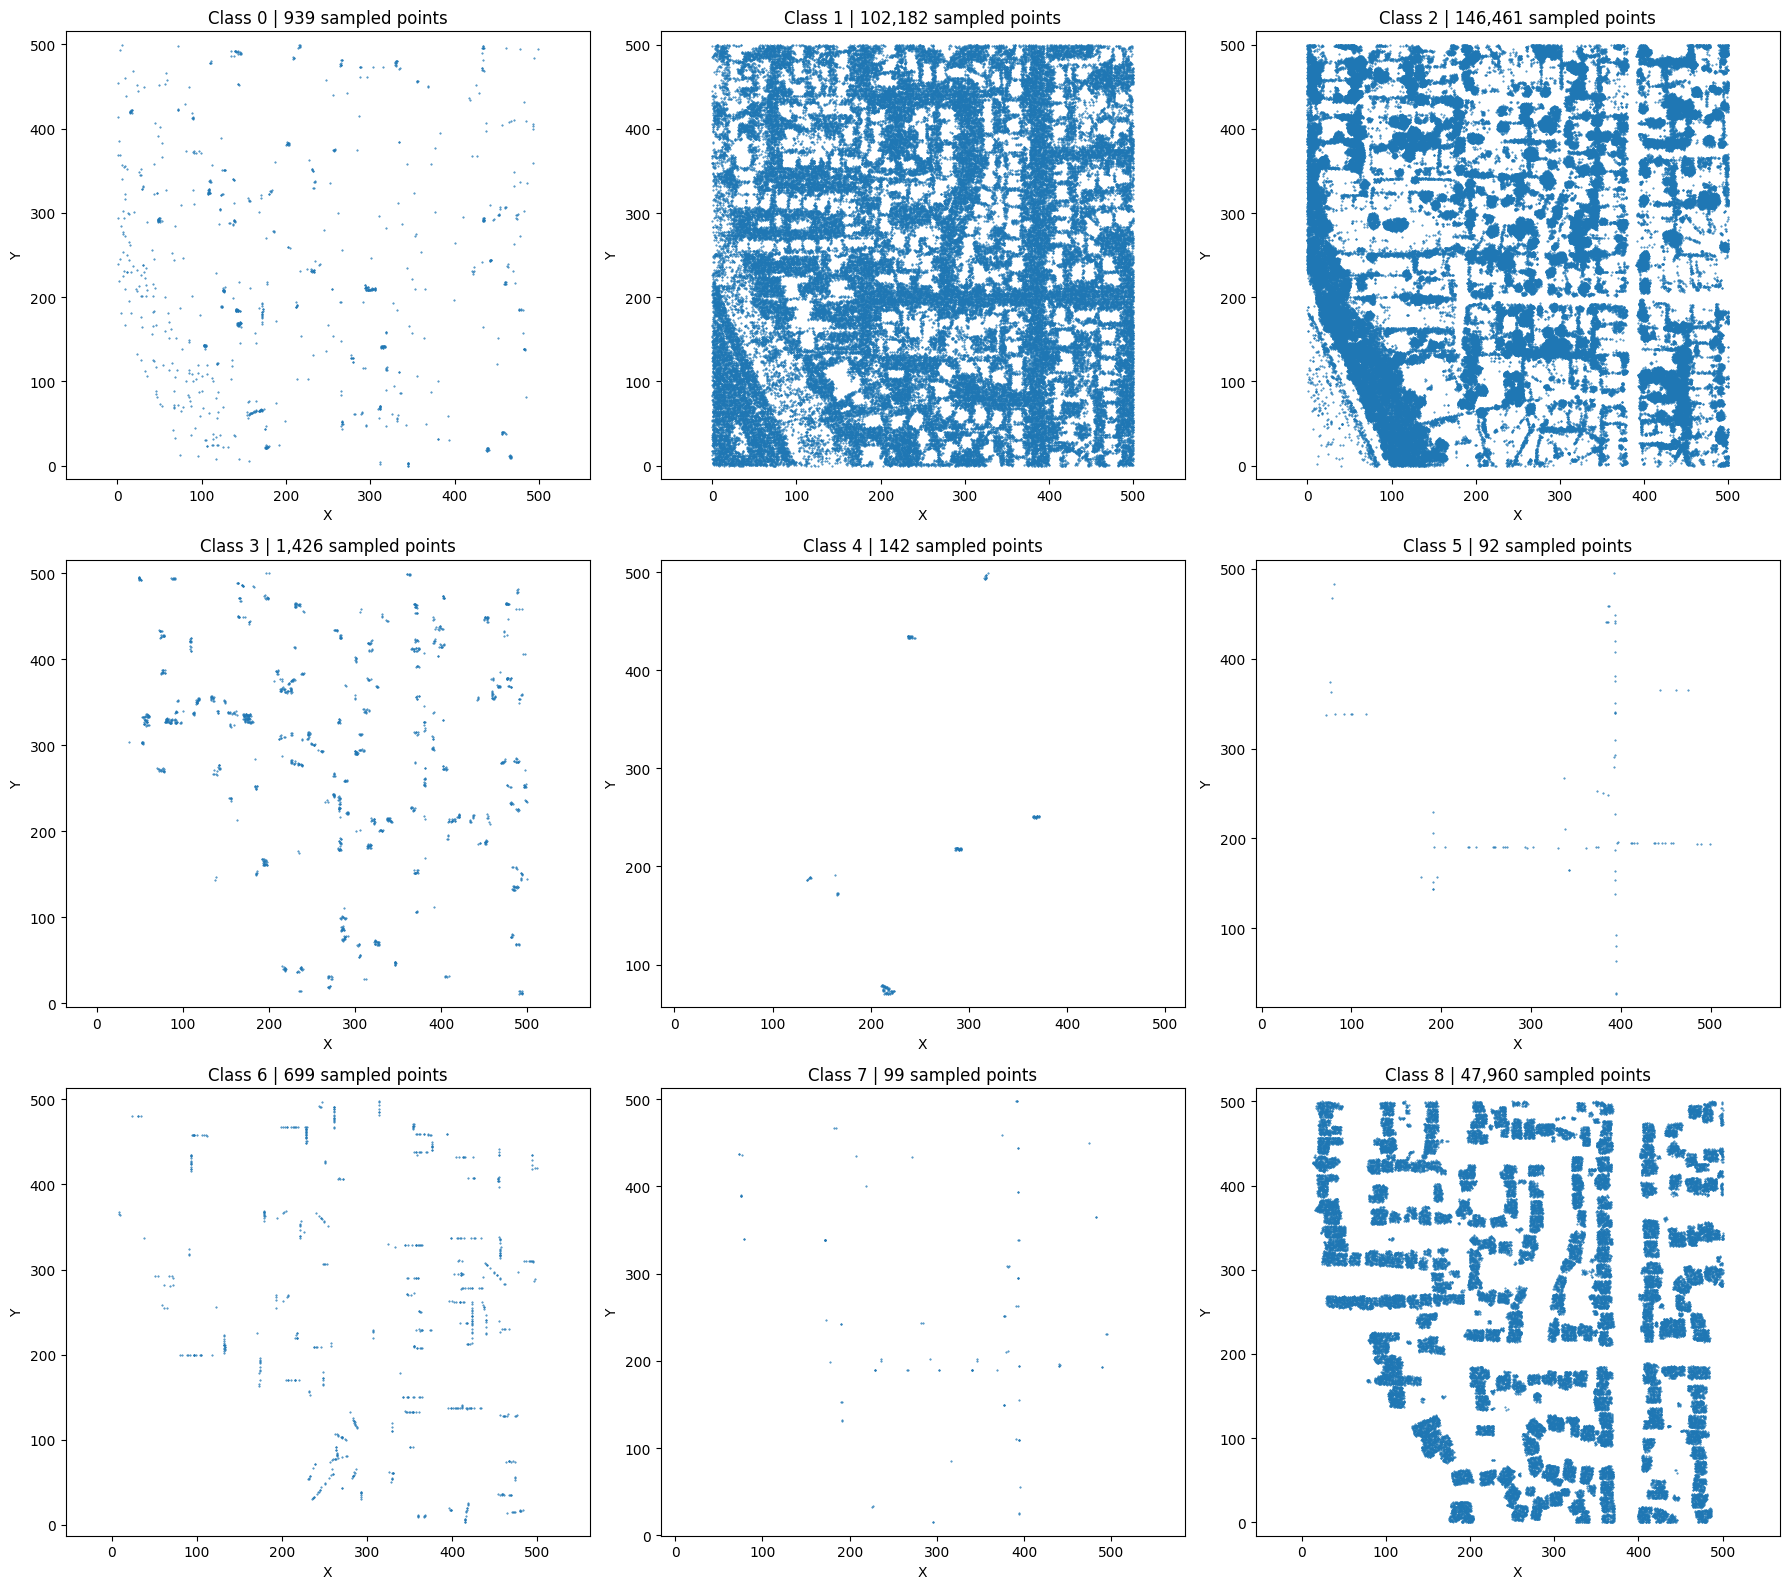

In [28]:
import matplotlib.pyplot as plt

sample_size = min(300000, len(points_normalized))

indices = np.random.choice(
    len(points_normalized),
    sample_size,
    replace=False
)

sample_points = points_normalized[indices]
sample_labels = classification[indices]

labels = np.unique(sample_labels)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(18, 16)
)

axes = axes.flatten()

for ax, label in zip(axes, labels):
    mask = sample_labels == label

    ax.scatter(
        sample_points[mask, 0],
        sample_points[mask, 1],
        s=0.2
    )

    ax.set_title(
        f"Class {label} | {mask.sum():,} sampled points"
    )

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.axis("equal")

for ax in axes[len(labels):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [29]:
for label in np.unique(classification):
    label_z = points_normalized[classification == label, 2]

    print(
        f"Label {label}: "
        f"min={label_z.min():.2f}, "
        f"max={label_z.max():.2f}, "
        f"mean={label_z.mean():.2f}, "
        f"count={len(label_z):,}"
    )

Label 0: min=0.00, max=67.80, mean=43.72, count=43,787
Label 1: min=1.70, max=53.20, mean=42.88, count=4,926,289
Label 2: min=1.78, max=90.60, mean=52.64, count=7,014,400
Label 3: min=42.39, max=54.05, mean=47.97, count=69,005
Label 4: min=44.62, max=52.39, mean=47.74, count=6,277
Label 5: min=47.15, max=62.85, mean=54.24, count=4,420
Label 6: min=42.72, max=54.52, mean=48.22, count=33,399
Label 7: min=45.91, max=62.72, mean=53.90, count=4,654
Label 8: min=40.20, max=63.18, mean=51.37, count=2,292,518


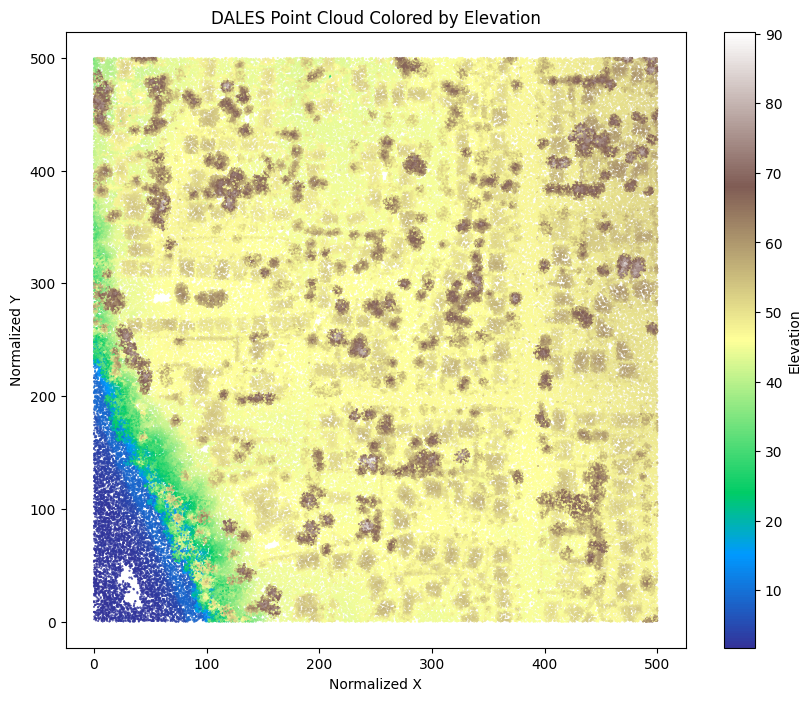

In [30]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    sample_points[:, 0],
    sample_points[:, 1],
    c=sample_points[:, 2],
    s=0.2,
    cmap="terrain"
)

plt.xlabel("Normalized X")
plt.ylabel("Normalized Y")
plt.title("DALES Point Cloud Colored by Elevation")
plt.axis("equal")

plt.colorbar(scatter, label="Elevation")
plt.show()

In [31]:
label_statistics = []

for label in np.unique(classification):
    mask = classification == label
    label_points = points_normalized[mask]

    label_statistics.append({
        "label": int(label),
        "point_count": int(mask.sum()),
        "percentage": float(mask.sum() / len(classification) * 100),
        "z_min": float(label_points[:, 2].min()),
        "z_max": float(label_points[:, 2].max()),
        "z_mean": float(label_points[:, 2].mean())
    })

label_statistics_df = pd.DataFrame(label_statistics)

display(label_statistics_df)

,label,point_count,percentage,z_min,z_max,z_mean
0,0,43787,0.304187,0.000000,67.800003,43.723808
1,1,4926289,34.222820,1.700000,53.200001,42.876308
2,2,7014400,48.728880,1.780000,90.599998,52.638412
3,3,69005,0.479376,42.389999,54.049999,47.973743
4,4,6277,0.043606,44.619999,52.389999,47.737709
5,5,4420,0.030706,47.150002,62.849998,54.239685
6,6,33399,0.232022,42.720001,54.520000,48.222004
7,7,4654,0.032331,45.910000,62.720001,53.896446
8,8,2292518,15.926071,40.200001,63.180000,51.369701


# Building-Point Extraction

In [32]:
BUILDING_LABEL = 8

In [33]:
building_mask = classification == BUILDING_LABEL

building_points = points_normalized[building_mask]

print("Selected building label:", BUILDING_LABEL)
print("Number of building points:", len(building_points))
print(
    "Building percentage:",
    len(building_points) / len(points_normalized) * 100,
    "%"
)

Selected building label: 8
Number of building points: 2292518
Building percentage: 15.92607137505489 %


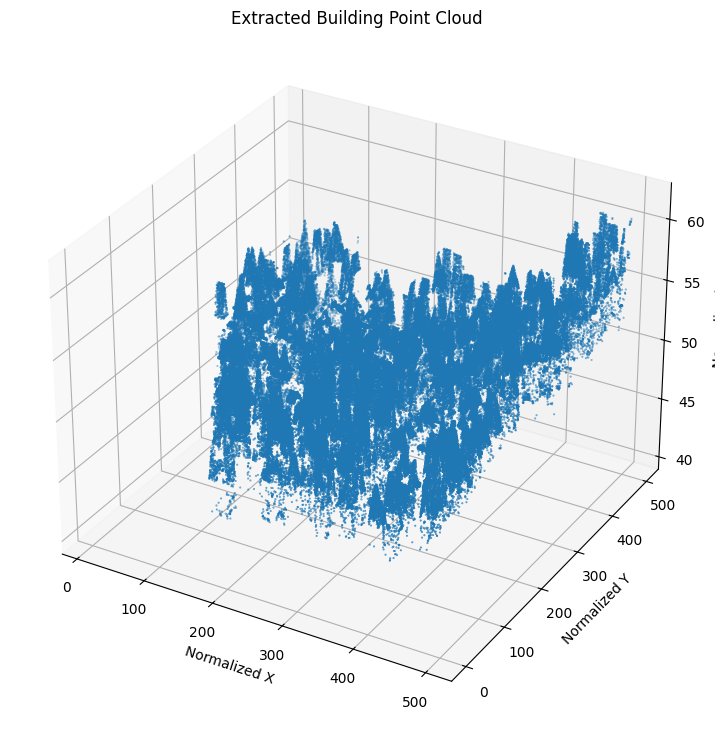

In [34]:
sample_size = min(200000, len(building_points))

indices = np.random.choice(
    len(building_points),
    sample_size,
    replace=False
)

building_sample = building_points[indices]

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    building_sample[:, 0],
    building_sample[:, 1],
    building_sample[:, 2],
    s=0.2
)

ax.set_title("Extracted Building Point Cloud")
ax.set_xlabel("Normalized X")
ax.set_ylabel("Normalized Y")
ax.set_zlabel("Normalized Z")

plt.show()

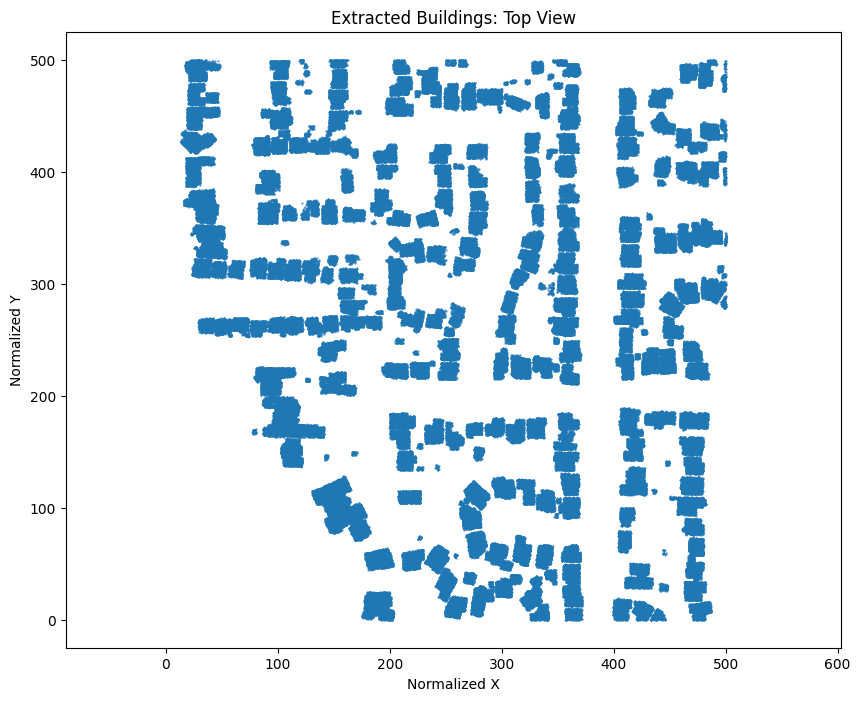

In [35]:
plt.figure(figsize=(10, 8))

plt.scatter(
    building_sample[:, 0],
    building_sample[:, 1],
    s=0.2
)

plt.title("Extracted Buildings: Top View")
plt.xlabel("Normalized X")
plt.ylabel("Normalized Y")
plt.axis("equal")

plt.show()

# Ground Removal and Height Normalization


In [36]:
ground_z = np.percentile(points_normalized[:, 2], 5)

print("Estimated ground elevation:", ground_z)

Estimated ground elevation: 27.87


In [37]:
building_points_relative = building_points.copy()

building_points_relative[:, 2] -= ground_z

building_points_relative[:, 2] = np.maximum(
    building_points_relative[:, 2],
    0
)

print("Relative building height range:")
print(
    building_points_relative[:, 2].min(),
    "to",
    building_points_relative[:, 2].max()
)

Relative building height range:
12.33 to 35.309998


In [38]:
DENSE_POINTS = 200000

dense_count = min(
    DENSE_POINTS,
    len(building_points_relative)
)

dense_indices = np.random.choice(
    len(building_points_relative),
    dense_count,
    replace=False
)

dense_points = building_points_relative[dense_indices]

print("Dense point cloud shape:", dense_points.shape)

Dense point cloud shape: (200000, 3)


In [39]:
SPARSE_RATIO = 0.25

sparse_count = int(
    len(dense_points) * SPARSE_RATIO
)

sparse_indices = np.random.choice(
    len(dense_points),
    sparse_count,
    replace=False
)

sparse_points = dense_points[sparse_indices]

print("Sparse point cloud shape:", sparse_points.shape)

Sparse point cloud shape: (50000, 3)


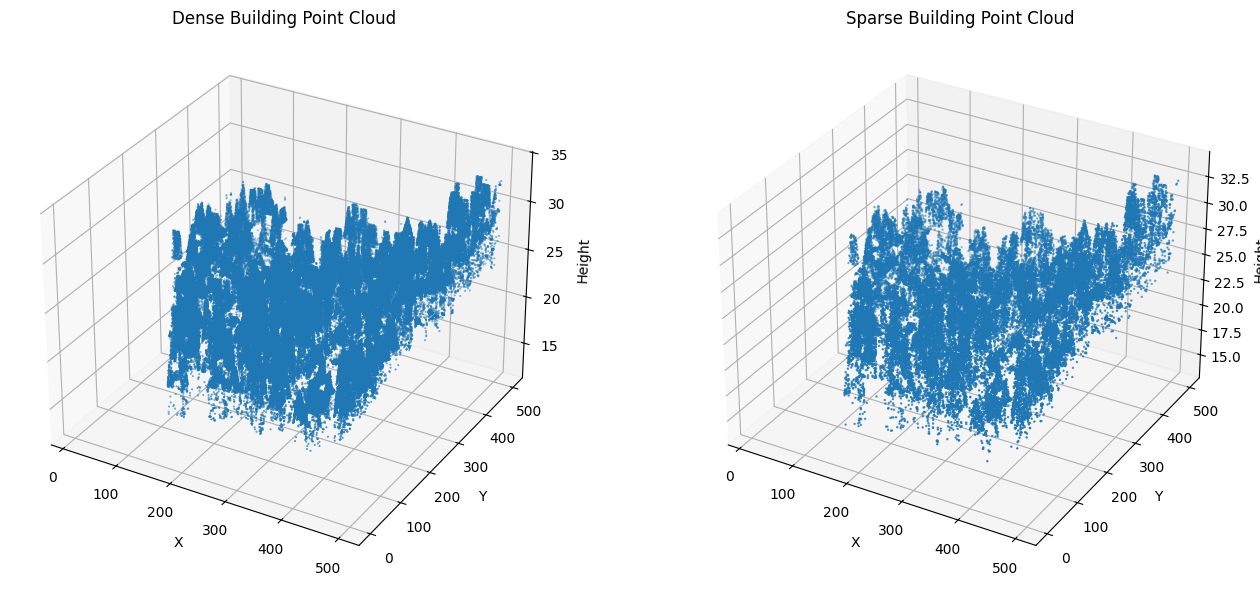

In [40]:
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection="3d")
ax1.scatter(
    dense_points[:, 0],
    dense_points[:, 1],
    dense_points[:, 2],
    s=0.2
)
ax1.set_title("Dense Building Point Cloud")

ax2 = fig.add_subplot(122, projection="3d")
ax2.scatter(
    sparse_points[:, 0],
    sparse_points[:, 1],
    sparse_points[:, 2],
    s=0.5
)
ax2.set_title("Sparse Building Point Cloud")

for ax in [ax1, ax2]:
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Height")

plt.tight_layout()
plt.show()

In [41]:
np.save("/kaggle/working/dense_building.npy", dense_points)
np.save("/kaggle/working/sparse_building.npy", sparse_points)

print("Dense saved:", dense_points.shape)
print("Sparse saved:", sparse_points.shape)

Dense saved: (200000, 3)
Sparse saved: (50000, 3)


In [42]:
print("Dense shape:", dense_points.shape)
print("Minimum:", dense_points.min(axis=0))
print("Maximum:", dense_points.max(axis=0))

Dense shape: (200000, 3)
Minimum: [13.34375   0.       12.729998]
Maximum: [500.03125 500.       33.58   ]


In [43]:
import numpy as np

def voxelize(points, voxel_size=1.0):
    """
    Convert XYZ point cloud into occupied voxel coordinates.

    voxel_size:
        Size of each voxel in coordinate units.
    """

    points = np.asarray(points, dtype=np.float32)

    min_bound = points.min(axis=0)

    voxel_indices = np.floor(
        (points - min_bound) / voxel_size
    ).astype(np.int32)

    unique_voxels = np.unique(
        voxel_indices,
        axis=0
    )

    return unique_voxels, min_bound

In [44]:
voxel_size = 1.0

dense_voxels, min_bound = voxelize(
    dense_points,
    voxel_size=voxel_size
)

print("Original points:", len(dense_points))
print("Occupied voxels:", len(dense_voxels))
print("Voxel size:", voxel_size)

Original points: 200000
Occupied voxels: 85108
Voxel size: 1.0


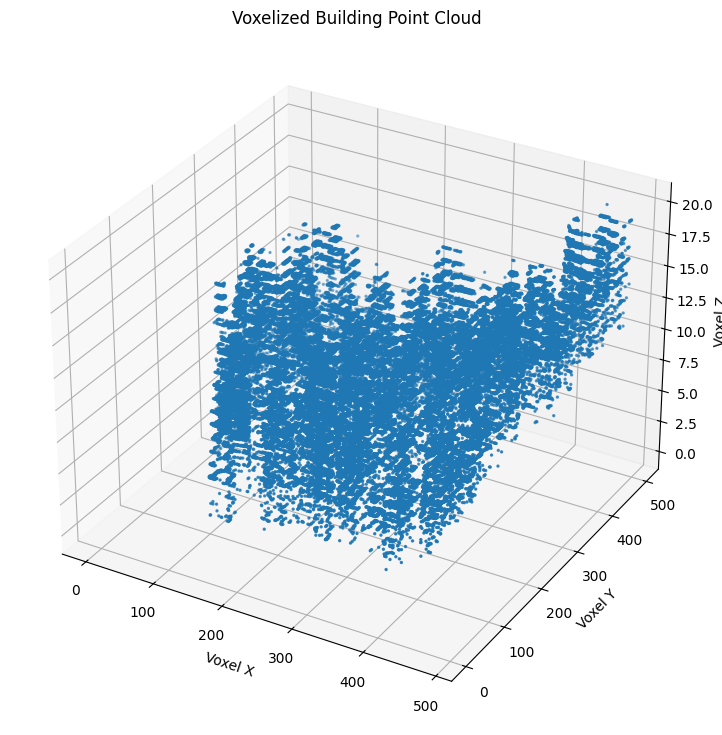

In [45]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    dense_voxels[:, 0],
    dense_voxels[:, 1],
    dense_voxels[:, 2],
    s=2
)

ax.set_title("Voxelized Building Point Cloud")
ax.set_xlabel("Voxel X")
ax.set_ylabel("Voxel Y")
ax.set_zlabel("Voxel Z")

plt.show()

In [46]:
voxel_sizes = [0.5, 1.0, 2.0, 5.0]

for size in voxel_sizes:
    voxels, _ = voxelize(
        dense_points,
        voxel_size=size
    )

    print(
        f"Voxel size {size} m: "
        f"{len(voxels):,} occupied voxels"
    )


Voxel size 0.5 m: 153,924 occupied voxels
Voxel size 1.0 m: 85,108 occupied voxels
Voxel size 2.0 m: 32,398 occupied voxels
Voxel size 5.0 m: 6,575 occupied voxels


In [47]:
voxel_sizes = [0.5, 1.0, 2.0, 5.0]

for size in voxel_sizes:
    voxels, _ = voxelize(
        dense_points,
        voxel_size=size
    )

    print(
        f"Voxel size {size} m: "
        f"{len(voxels):,} occupied voxels"
    )

Voxel size 0.5 m: 153,924 occupied voxels
Voxel size 1.0 m: 85,108 occupied voxels
Voxel size 2.0 m: 32,398 occupied voxels
Voxel size 5.0 m: 6,575 occupied voxels


In [48]:
def voxelize_with_origin(points, voxel_size=1.0, origin=None):
    points = np.asarray(points, dtype=np.float32)

    if origin is None:
        origin = points.min(axis=0)

    voxel_indices = np.floor(
        (points - origin) / voxel_size
    ).astype(np.int32)

    unique_voxels = np.unique(
        voxel_indices,
        axis=0
    )

    return unique_voxels, origin

In [49]:
dense_voxels, origin = voxelize_with_origin(
    dense_points,
    voxel_size=1.0
)

sparse_voxels, _ = voxelize_with_origin(
    sparse_points,
    voxel_size=1.0,
    origin=origin
)

print("Dense voxels:", len(dense_voxels))
print("Sparse voxels:", len(sparse_voxels))

Dense voxels: 85108
Sparse voxels: 38269


In [50]:
np.save(
    "/kaggle/working/dense_voxels.npy",
    dense_voxels
)

np.save(
    "/kaggle/working/sparse_voxels.npy",
    sparse_voxels
)

np.save(
    "/kaggle/working/voxel_origin.npy",
    origin
)

print("Voxel files saved successfully.")

Voxel files saved successfully.


# Divide the Point Cloud into Fixed-Size Blocks

In [51]:
VOXEL_SIZE = 1.0
BLOCK_SIZE = 32

In [52]:
def extract_blocks(points, voxel_size=1.0, block_size=32, min_points=100):
    """
    Divide a point cloud into fixed-size spatial blocks.

    Returns:
        List of point-cloud blocks
        List of block origins
    """

    points = np.asarray(points, dtype=np.float32)

    origin = points.min(axis=0)

    voxel_indices = np.floor(
        (points - origin) / voxel_size
    ).astype(np.int32)

    block_indices = voxel_indices // block_size

    unique_blocks = np.unique(
        block_indices,
        axis=0
    )

    blocks = []
    origins = []

    for block_index in unique_blocks:
        mask = np.all(
            block_indices == block_index,
            axis=1
        )

        block_points = points[mask]

        if len(block_points) < min_points:
            continue

        block_origin = (
            origin + block_index * block_size * voxel_size
        )

        blocks.append(block_points)
        origins.append(block_origin)

    return blocks, origins

In [53]:
dense_blocks, dense_origins = extract_blocks(
    dense_points,
    voxel_size=VOXEL_SIZE,
    block_size=BLOCK_SIZE,
    min_points=100
)

print("Number of dense blocks:", len(dense_blocks))

for i, block in enumerate(dense_blocks[:5]):
    print(f"Block {i}: {block.shape}")

Number of dense blocks: 199
Block 0: (667, 3)
Block 1: (945, 3)
Block 2: (1985, 3)
Block 3: (2328, 3)
Block 4: (1463, 3)


In [54]:
def extract_blocks_with_origin(
    points,
    origin,
    voxel_size=1.0,
    block_size=32,
    min_points=10
):
    points = np.asarray(points, dtype=np.float32)

    voxel_indices = np.floor(
        (points - origin) / voxel_size
    ).astype(np.int32)

    block_indices = voxel_indices // block_size

    unique_blocks = np.unique(
        block_indices,
        axis=0
    )

    blocks = []
    block_ids = []

    for block_index in unique_blocks:
        mask = np.all(
            block_indices == block_index,
            axis=1
        )

        block_points = points[mask]

        if len(block_points) < min_points:
            continue

        blocks.append(block_points)
        block_ids.append(tuple(block_index))

    return blocks, block_ids

In [55]:
scene_origin = points_normalized.min(axis=0)

dense_blocks, dense_ids = extract_blocks_with_origin(
    dense_points,
    scene_origin,
    voxel_size=VOXEL_SIZE,
    block_size=BLOCK_SIZE,
    min_points=100
)

sparse_blocks, sparse_ids = extract_blocks_with_origin(
    sparse_points,
    scene_origin,
    voxel_size=VOXEL_SIZE,
    block_size=BLOCK_SIZE,
    min_points=10
)

print("Dense blocks:", len(dense_blocks))
print("Sparse blocks:", len(sparse_blocks))

Dense blocks: 207
Sparse blocks: 223


In [56]:
dense_dict = {
    block_id: block
    for block_id, block in zip(dense_ids, dense_blocks)
}

sparse_dict = {
    block_id: block
    for block_id, block in zip(sparse_ids, sparse_blocks)
}

common_ids = sorted(
    set(dense_dict.keys()) & set(sparse_dict.keys())
)

print("Matching block pairs:", len(common_ids))

Matching block pairs: 207


Dense block: (339, 3)
Sparse block: (85, 3)
Block ID: (np.int32(0), np.int32(9), np.int32(0))


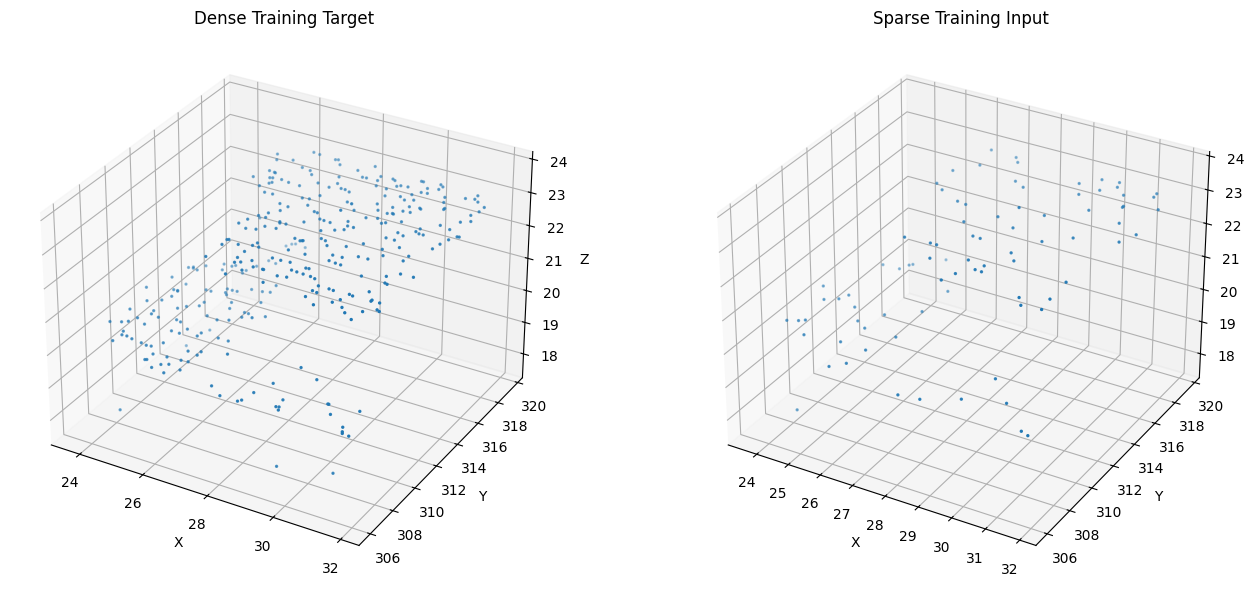

In [57]:
pair_id = common_ids[0]

dense_block = dense_dict[pair_id]
sparse_block = sparse_dict[pair_id]

print("Dense block:", dense_block.shape)
print("Sparse block:", sparse_block.shape)
print("Block ID:", pair_id)
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection="3d")
ax1.scatter(
    dense_block[:, 0],
    dense_block[:, 1],
    dense_block[:, 2],
    s=2
)
ax1.set_title("Dense Training Target")

ax2 = fig.add_subplot(122, projection="3d")
ax2.scatter(
    sparse_block[:, 0],
    sparse_block[:, 1],
    sparse_block[:, 2],
    s=2
)
ax2.set_title("Sparse Training Input")

for ax in [ax1, ax2]:
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

plt.tight_layout()
plt.show()

In [58]:
def normalize_block(block):
    block = block.copy()

    block_min = block.min(axis=0)
    block_max = block.max(axis=0)

    normalized = block - block_min

    return normalized, block_min, block_max

In [59]:
dense_block_norm, dense_min, dense_max = normalize_block(dense_block)
sparse_block_norm, _, _ = normalize_block(sparse_block)

print("Dense normalized range:")
print(dense_block_norm.min(axis=0))
print(dense_block_norm.max(axis=0))

Dense normalized range:
[0. 0. 0.]
[ 8.25      13.5        6.1000023]


In [60]:
def normalize_pair(dense_block, sparse_block):
    combined = np.vstack([dense_block, sparse_block])

    block_min = combined.min(axis=0)

    dense_normalized = dense_block - block_min
    sparse_normalized = sparse_block - block_min

    return dense_normalized, sparse_normalized, block_min

In [61]:
dense_block_norm, sparse_block_norm, block_min = normalize_pair(
    dense_block,
    sparse_block
)

In [62]:
import os

OUTPUT_DIR = "/kaggle/working/blocks"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for i, block_id in enumerate(common_ids):
    dense_block = dense_dict[block_id]
    sparse_block = sparse_dict[block_id]

    dense_norm, sparse_norm, block_min = normalize_pair(
        dense_block,
        sparse_block
    )

    np.save(
        f"{OUTPUT_DIR}/dense_{i:04d}.npy",
        dense_norm
    )

    np.save(
        f"{OUTPUT_DIR}/sparse_{i:04d}.npy",
        sparse_norm
    )

print("Saved block pairs:", len(common_ids))

Saved block pairs: 207


# Fixed-Size Point Sampling

In [63]:
def sample_fixed_points(points, num_points=2048):
    """
    Return exactly num_points from a point cloud.
    Randomly samples if there are too many points.
    Repeats points if there are too few.
    """

    points = np.asarray(points, dtype=np.float32)

    if len(points) == 0:
        raise ValueError("Point cloud is empty.")

    if len(points) >= num_points:
        indices = np.random.choice(
            len(points),
            num_points,
            replace=False
        )
    else:
        indices = np.random.choice(
            len(points),
            num_points,
            replace=True
        )

    return points[indices]

In [64]:
test_sample = sample_fixed_points(
    sparse_block,
    num_points=2048
)

print("Original sparse block:", sparse_block.shape)
print("Sampled sparse block:", test_sample.shape)

Original sparse block: (161, 3)
Sampled sparse block: (2048, 3)


In [65]:
INPUT_POINTS = 2048
TARGET_POINTS = 4096

training_inputs = []
training_targets = []
training_ids = []

for block_id in common_ids:
    dense_block = dense_dict[block_id]
    sparse_block = sparse_dict[block_id]

    dense_norm, sparse_norm, block_min = normalize_pair(
        dense_block,
        sparse_block
    )

    sparse_sample = sample_fixed_points(
        sparse_norm,
        INPUT_POINTS
    )

    dense_sample = sample_fixed_points(
        dense_norm,
        TARGET_POINTS
    )

    training_inputs.append(sparse_sample)
    training_targets.append(dense_sample)
    training_ids.append(block_id)

print("Training pairs created:", len(training_inputs))
print("Input shape:", training_inputs[0].shape)
print("Target shape:", training_targets[0].shape)

Training pairs created: 207
Input shape: (2048, 3)
Target shape: (4096, 3)


In [66]:
X = np.stack(training_inputs).astype(np.float32)
Y = np.stack(training_targets).astype(np.float32)

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (207, 2048, 3)
Y shape: (207, 4096, 3)


In [67]:
from sklearn.model_selection import train_test_split

X_train, X_val, Y_train, Y_val = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

print("Training inputs:", X_train.shape)
print("Validation inputs:", X_val.shape)
print("Training targets:", Y_train.shape)
print("Validation targets:", Y_val.shape)

Training inputs: (165, 2048, 3)
Validation inputs: (42, 2048, 3)
Training targets: (165, 4096, 3)
Validation targets: (42, 4096, 3)


In [68]:
np.save("/kaggle/working/X_train.npy", X_train)
np.save("/kaggle/working/Y_train.npy", Y_train)
np.save("/kaggle/working/X_val.npy", X_val)
np.save("/kaggle/working/Y_val.npy", Y_val)

print("Processed training dataset saved.")

Processed training dataset saved.


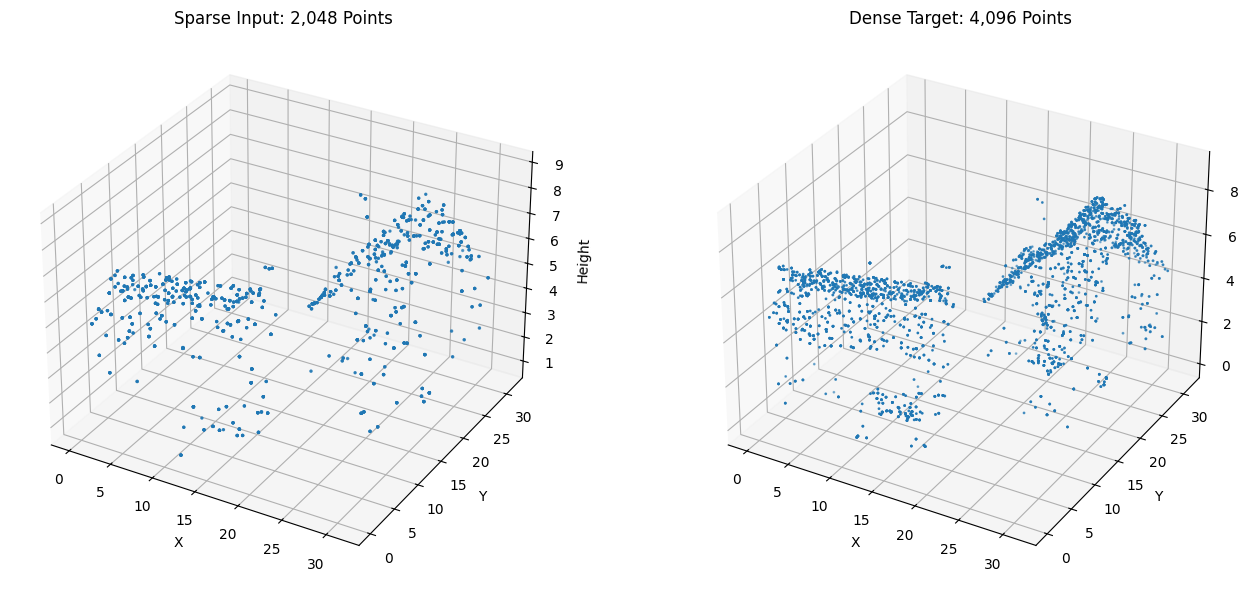

In [69]:
pair_index = 0

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection="3d")
ax1.scatter(
    X_train[pair_index, :, 0],
    X_train[pair_index, :, 1],
    X_train[pair_index, :, 2],
    s=2
)
ax1.set_title("Sparse Input: 2,048 Points")

ax2 = fig.add_subplot(122, projection="3d")
ax2.scatter(
    Y_train[pair_index, :, 0],
    Y_train[pair_index, :, 1],
    Y_train[pair_index, :, 2],
    s=1
)
ax2.set_title("Dense Target: 4,096 Points")

for ax in [ax1, ax2]:
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Height")

plt.tight_layout()
plt.show()

# Realistic Sparse-Point Simulation and Data Augmentation

In [70]:
def simulate_sparse_cloud(
    dense_points,
    keep_ratio=0.25,
    height_dropout=False
):
    points = dense_points.copy()

    if height_dropout:
        height = points[:, 2]
        height_probability = np.clip(
            0.3 + 0.7 * (height / (height.max() + 1e-8)),
            0.3,
            1.0
        )
    else:
        height_probability = np.ones(len(points))

    scores = np.random.rand(len(points)) * height_probability

    keep_count = int(len(points) * keep_ratio)

    selected_indices = np.argsort(scores)[-keep_count:]

    return points[selected_indices]

In [71]:
augmented_sparse = simulate_sparse_cloud(
    dense_points,
    keep_ratio=0.25,
    height_dropout=True
)

print("Dense points:", dense_points.shape)
print("Sparse points:", augmented_sparse.shape)

Dense points: (200000, 3)
Sparse points: (50000, 3)


In [72]:
def add_lidar_noise(points, noise_std=0.02):
    noise = np.random.normal(
        loc=0.0,
        scale=noise_std,
        size=points.shape
    ).astype(np.float32)

    return points + noise

In [73]:
noisy_sparse = add_lidar_noise(
    augmented_sparse,
    noise_std=0.02
)

print(noisy_sparse.shape)

(50000, 3)


In [74]:
def random_rotate_z(points):
    angle = np.random.uniform(0, 2 * np.pi)

    rotation_matrix = np.array([
        [np.cos(angle), -np.sin(angle), 0],
        [np.sin(angle),  np.cos(angle), 0],
        [0,              0,             1]
    ], dtype=np.float32)

    return points @ rotation_matrix.T

In [75]:
rotated_sparse = random_rotate_z(noisy_sparse)

print(rotated_sparse.shape)

(50000, 3)


In [76]:
def augment_sparse_cloud(dense_points):
    sparse = simulate_sparse_cloud(
        dense_points,
        keep_ratio=np.random.uniform(0.15, 0.4),
        height_dropout=True
    )

    sparse = add_lidar_noise(
        sparse,
        noise_std=np.random.uniform(0.005, 0.02)
    )

    sparse = random_rotate_z(sparse)

    return sparse

In [77]:
augmented_sparse = augment_sparse_cloud(dense_points)

print("Dense:", dense_points.shape)
print("Augmented sparse:", augmented_sparse.shape)

Dense: (200000, 3)
Augmented sparse: (66249, 3)


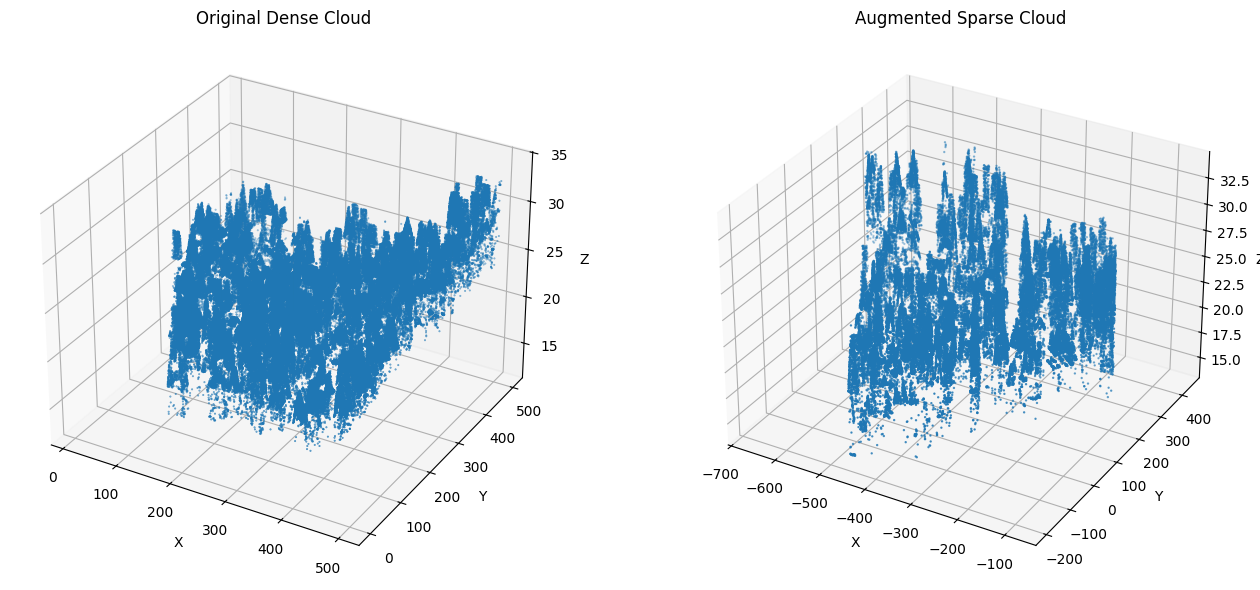

In [78]:
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection="3d")
ax1.scatter(
    dense_points[:, 0],
    dense_points[:, 1],
    dense_points[:, 2],
    s=0.2
)
ax1.set_title("Original Dense Cloud")

ax2 = fig.add_subplot(122, projection="3d")
ax2.scatter(
    augmented_sparse[:, 0],
    augmented_sparse[:, 1],
    augmented_sparse[:, 2],
    s=0.5
)
ax2.set_title("Augmented Sparse Cloud")

for ax in [ax1, ax2]:
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

plt.tight_layout()
plt.show()

In [79]:
INPUT_POINTS = 2048
TARGET_POINTS = 4096

X = []
Y = []

for block_id in common_ids:
    dense_block = dense_dict[block_id]

    dense_norm, _, _ = normalize_block(dense_block)

    sparse_augmented = augment_sparse_cloud(dense_norm)

    sparse_sample = sample_fixed_points(
        sparse_augmented,
        INPUT_POINTS
    )

    dense_sample = sample_fixed_points(
        dense_norm,
        TARGET_POINTS
    )

    X.append(sparse_sample)
    Y.append(dense_sample)

X = np.stack(X).astype(np.float32)
Y = np.stack(Y).astype(np.float32)

print("X:", X.shape)
print("Y:", Y.shape)

X: (207, 2048, 3)
Y: (207, 4096, 3)


In [80]:
np.save("/kaggle/working/X_augmented.npy", X)
np.save("/kaggle/working/Y_augmented.npy", Y)

print("Augmented dataset saved.")

Augmented dataset saved.
